# Experiment C — Part 2: combined preprocessing

Compare original images against one ordered pipeline: **grayscale → non-local means denoising → deskewing → CLAHE**. Every line passes through all four steps before the mandatory TrOCR processor transforms. The order is fixed before running and is recorded in metadata; changing it defines a different experiment.

Use the same 100 seeded IAM validation lines, dataset/model commits, decoding, and normalization as Part 1. This tests the combined treatment; it cannot attribute a change to a particular step or establish that this order is optimal. Grayscale is redundant for already-L images. No training or test-set evaluation is performed.

Primary outcomes are corpus CER/WER (lower is better). Scoring collapses whitespace and retains case and punctuation. These development results do not establish statistical significance. Set SAMPLE_COUNT to None for the full validation split.

In [1]:
from pathlib import Path
import sys
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.load_dataset.iam import load_iam_dataset, get_sample
from src.models import TrOCRRecognizer
from src.preprocessing import (PreprocessingPipeline, Grayscale, NonLocalMeans, Deskew, CLAHE)
from src.evaluation import compare_recognition

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
SPLIT = "validation"
DATASET_REVISION = "fbdad97500ce54635c0d1ba306bf535cb40656cf"
CHECKPOINT = "microsoft/trocr-base-handwritten"
MODEL_REVISION = "eaacaf452b06415df8f10bb6fad3a4c11e609406"
DEVICE = "cpu"
SAMPLE_COUNT = 100
SEED = 5112
GENERATION = {"max_new_tokens": 128, "num_beams": 1, "do_sample": False}
combined = PreprocessingPipeline((
    Grayscale(),
    NonLocalMeans(h=3.0, h_color=3.0),
    Deskew(max_angle=10.0, angle_step=0.5),
    CLAHE(clip_limit=2.0, tile_grid_size=(8, 8)),
))
pipelines = {"baseline": PreprocessingPipeline(), "combined": combined}
assert SPLIT == "validation", "Keep test data reserved for final evaluation."
print(json.dumps({name: pipe.to_config() for name, pipe in pipelines.items()}, indent=2))

{
  "baseline": {
    "steps": []
  },
  "combined": {
    "steps": [
      {
        "name": "grayscale",
        "enabled": true,
        "output_mode": "L"
      },
      {
        "name": "non_local_means",
        "enabled": true,
        "h": 3.0,
        "h_color": 3.0,
        "template_window_size": 7,
        "search_window_size": 21
      },
      {
        "name": "deskew",
        "enabled": true,
        "max_angle": 10.0,
        "angle_step": 0.5,
        "estimator": "otsu_projection_difference",
        "resampling": "bicubic",
        "expand": true,
        "fill": "white"
      },
      {
        "name": "clahe",
        "enabled": true,
        "clip_limit": 2.0,
        "tile_grid_size": [
          8,
          8
        ],
        "processing": "grayscale directly; RGB via LAB luminance"
      }
    ]
  }
}


In [3]:
dataset = load_iam_dataset(split=SPLIT, revision=DATASET_REVISION)
assert {"image", "text"}.issubset(dataset.column_names)
if SAMPLE_COUNT is None:
    indices = list(range(len(dataset)))
else:
    assert type(SAMPLE_COUNT) is int and 0 < SAMPLE_COUNT <= len(dataset)
    indices = sorted(np.random.default_rng(SEED).choice(len(dataset), SAMPLE_COUNT, replace=False).tolist())
samples = [get_sample(dataset, i) for i in indices]
assert len({s["id"] for s in samples}) == len(samples)
assert all(isinstance(s["ground_truth"], str) and s["ground_truth"].strip() for s in samples)
assert all(s["image"].mode in ("L", "RGB") for s in samples)
sample_info = pd.DataFrame([{
    "sample_id": s["id"], "dataset_index": i, "mode": s["image"].mode,
    "width": s["image"].width, "height": s["image"].height,
    "reference_characters": len(s["ground_truth"]), "ground_truth": s["ground_truth"],
} for i, s in zip(indices, samples)])
print(f"IAM {SPLIT}: {len(dataset)} available; {len(samples)} selected; revision {DATASET_REVISION}")
display(sample_info.head())
display(sample_info["mode"].value_counts().rename("selected_images").to_frame())
grayscale_is_identity = all(s["image"].mode == "L" for s in samples)
print("Grayscale is pixel-identical to baseline on this selected set:", grayscale_is_identity)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


IAM validation: 976 available; 100 selected; revision fbdad97500ce54635c0d1ba306bf535cb40656cf


,sample_id,dataset_index,mode,width,height,reference_characters,ground_truth
0,sample_3,3,L,1355,128,43,with James Maxwell making a fine job of the
1,sample_43,43,L,2250,128,43,"15,695 times in their different grammatical"
2,sample_48,48,L,2187,128,37,large . But the British text includes
3,sample_54,54,L,2305,128,39,"the difference between the 15,695 words"
4,sample_58,58,L,2135,128,33,in Neh. 2.8 and S. of Sol. 4.13 .


,selected_images
mode,
L,100


Grayscale is pixel-identical to baseline on this selected set: True


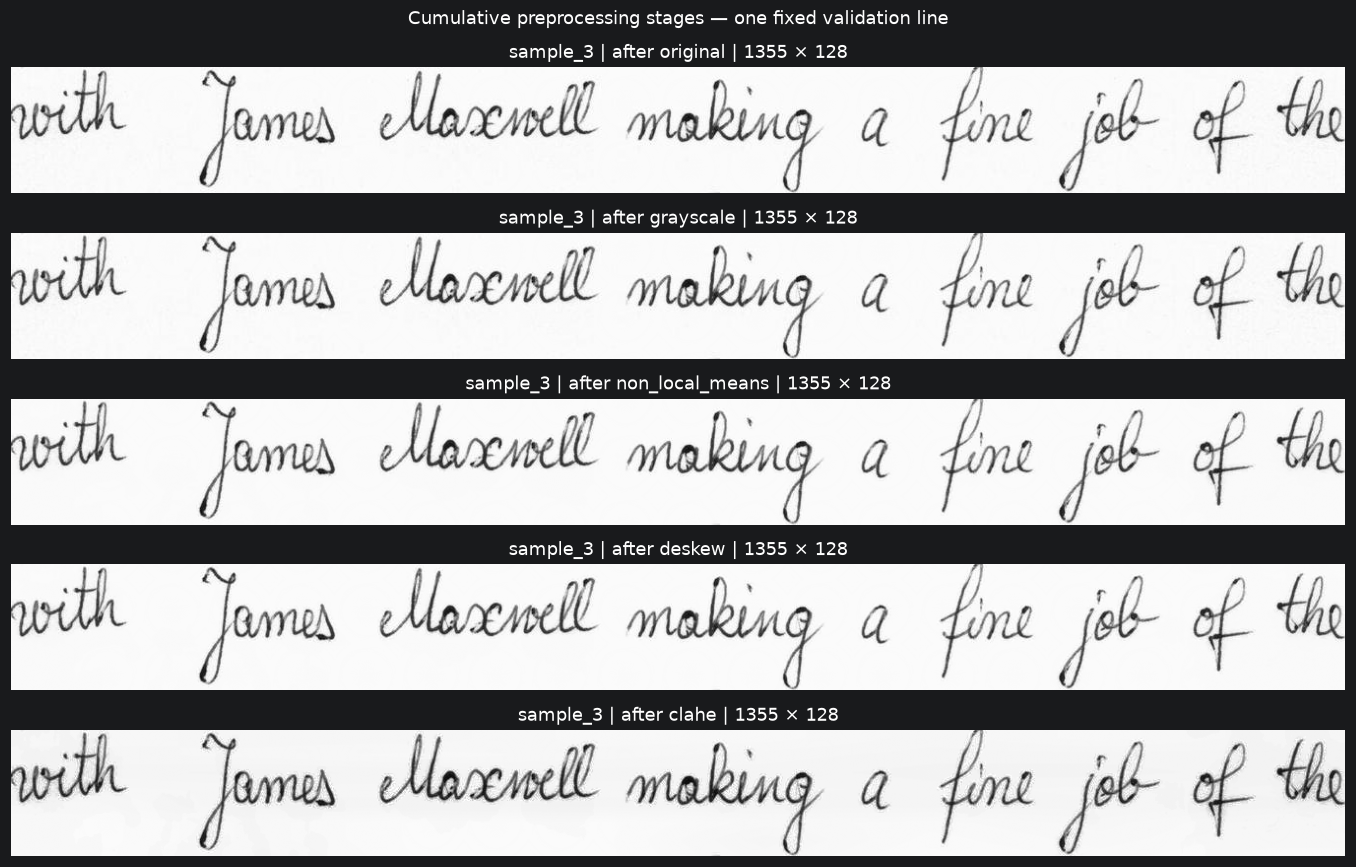

In [4]:
# Show cumulative stages on the first fixed sample, without inference.
preview_sample = samples[0]
stage_names = ["original"] + [step.to_config()["name"] for step in combined.steps]
fig, axes = plt.subplots(len(stage_names), 1, figsize=(15, 8), squeeze=False)
for i, stage_name in enumerate(stage_names):
    image = PreprocessingPipeline(combined.steps[:i])(preview_sample["image"])
    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"{preview_sample['id']} | after {stage_name} | {image.width} × {image.height}")
    axes[i, 0].axis("off")
fig.suptitle("Cumulative preprocessing stages — one fixed validation line")
fig.tight_layout()
# Save this preview with the result artifacts after recognition.
stage_preview_figure = fig
plt.show()

## Recognition and saved artifacts

Load the model once and run a warm-up outside recorded timings. Each treatment processes every selected line in the same order. Timing includes mandatory processor transforms and generation, excludes model loading, and records optional preprocessing separately. CPU timings are descriptive; this single sequential run is not a controlled speed benchmark.

A fresh results directory is written immediately after inference, before plotting. It contains raw predictions and references, corpus summaries, selected sample information, and reproducibility metadata. No existing results are overwritten.

In [5]:
model = TrOCRRecognizer(checkpoint=CHECKPOINT, revision=MODEL_REVISION,
                         device=DEVICE, generation_kwargs=GENERATION)
_ = model.predict(samples[0]["image"])  # Unscored warm-up.
rows, summaries = compare_recognition(samples, model, pipelines)
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries).set_index("configuration").loc[list(pipelines)]
assert (summary["scored_sample_count"] == len(samples)).all()
for name in pipelines:
    ids = predictions.loc[predictions["configuration"] == name, "sample_id"].tolist()
    assert ids == [s["id"] for s in samples]
for metric in ("cer", "wer"):
    baseline_value = summary.loc["baseline", metric]
    summary[f"{metric}_change_pp"] = 100 * (summary[metric] - baseline_value)
    summary[f"{metric}_relative_change_pct"] = (
        100 * (summary[metric] - baseline_value) / baseline_value if baseline_value else np.nan
    )
summary["preprocessing_seconds"] = predictions.groupby("configuration")["preprocessing_seconds"].sum()
summary["total_seconds"] = summary["preprocessing_seconds"] + summary["inference_seconds"]
summary["seconds_per_line"] = summary["total_seconds"] / summary["sample_count"]

run_id = "experiment_c_part_2_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = ROOT / "results" / run_id
run_dir.mkdir(parents=True, exist_ok=False)
metadata = {
    "experiment_id": run_id, "created_utc": datetime.now(timezone.utc).isoformat(),
    "experiment": "Combined preprocessing versus baseline; TrOCR; IAM validation",
    "dataset": "Teklia/IAM-line", "split": SPLIT, "dataset_revision": DATASET_REVISION,
    "dataset_fingerprint": dataset._fingerprint, "split_size": len(dataset),
    "sample_indices": indices, "sample_count": len(samples), "seed": SEED,
    "sampling": "all rows if SAMPLE_COUNT is None; otherwise seeded sampling without replacement, sorted indices",
    "model": model.to_config(),
    "preprocessing": {name: pipe.to_config() for name, pipe in pipelines.items()},
    "normalization": "collapse whitespace; strip edges; retain case and punctuation",
    "grayscale_is_identity": grayscale_is_identity,
    "timing": "wall seconds; warm-up excluded; model loading excluded; mandatory transforms included in inference",
    "python": platform.python_version(), "platform": platform.platform(),
    "versions": {p: version(p) for p in ("torch", "transformers", "datasets", "huggingface-hub",
        "jiwer", "numpy", "Pillow", "opencv-python-headless", "pandas", "matplotlib")},
}
predictions.to_csv(run_dir / "predictions.csv", index=False)
summary.to_csv(run_dir / "summary.csv")
sample_info.to_csv(run_dir / "samples.csv", index=False)
(run_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
display(summary)
print("Saved:", run_dir)
stage_preview_figure.savefig(run_dir / "preprocessing_stages.png", bbox_inches="tight")

W1108 19:11:57.201000 9771 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


baseline: 1/100
baseline: 2/100
baseline: 3/100
baseline: 4/100
baseline: 5/100
baseline: 6/100
baseline: 7/100
baseline: 8/100
baseline: 9/100
baseline: 10/100
baseline: 11/100
baseline: 12/100
baseline: 13/100
baseline: 14/100
baseline: 15/100
baseline: 16/100
baseline: 17/100
baseline: 18/100
baseline: 19/100
baseline: 20/100
baseline: 21/100
baseline: 22/100
baseline: 23/100
baseline: 24/100
baseline: 25/100
baseline: 26/100
baseline: 27/100
baseline: 28/100
baseline: 29/100
baseline: 30/100
baseline: 31/100
baseline: 32/100
baseline: 33/100
baseline: 34/100
baseline: 35/100
baseline: 36/100
baseline: 37/100
baseline: 38/100
baseline: 39/100
baseline: 40/100
baseline: 41/100
baseline: 42/100
baseline: 43/100
baseline: 44/100
baseline: 45/100
baseline: 46/100
baseline: 47/100
baseline: 48/100
baseline: 49/100
baseline: 50/100
baseline: 51/100
baseline: 52/100
baseline: 53/100
baseline: 54/100
baseline: 55/100
baseline: 56/100
baseline: 57/100
baseline: 58/100
baseline: 59/100
baseli

,sample_count,scored_sample_count,cer,wer,inference_seconds,cer_change_pp,cer_relative_change_pct,wer_change_pp,wer_relative_change_pct,preprocessing_seconds,total_seconds,seconds_per_line
configuration,,,,,,,,,,,,
baseline,100,100,0.007770,0.026077,84.218589,0.000000,0.000000,0.000000,0.000000,0.006196,84.224785,0.842248
combined,100,100,0.013657,0.039683,83.193550,0.588651,75.757576,1.360544,52.173913,8.504883,91.698433,0.916984


Saved: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/experiment_c_part_2_20261109T001454768234Z


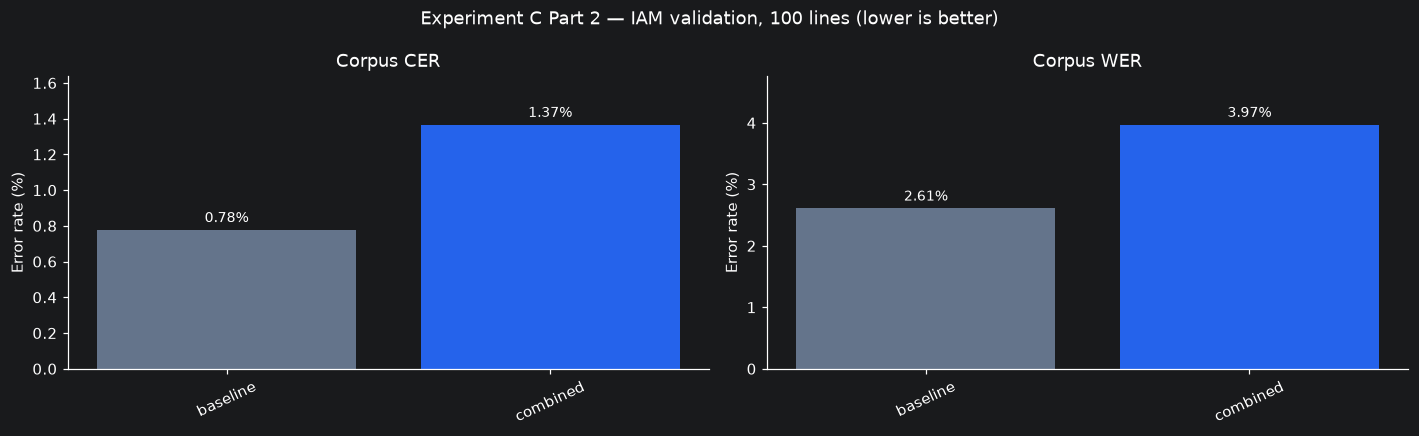

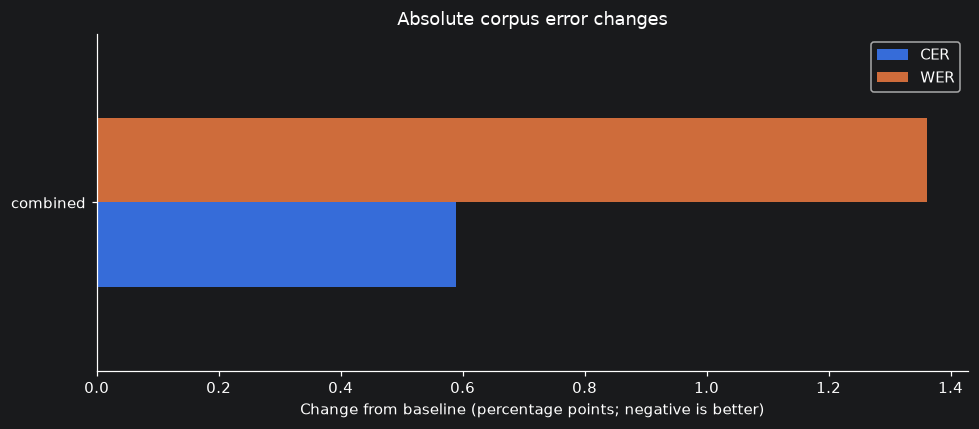

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ("cer", "wer")):
    values = 100 * summary[metric]
    bars = ax.bar(summary.index, values, color=["#64748b", "#2563eb"])
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=3, fontsize=9)
    ax.set(title=f"Corpus {metric.upper()}", ylabel="Error rate (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.margins(y=0.2)
fig.suptitle(f"Experiment C Part 2 — IAM validation, {len(samples)} lines (lower is better)")
fig.tight_layout()
fig.savefig(run_dir / "corpus_error_rates.png", bbox_inches="tight")
plt.show()

changes = summary.drop(index="baseline")[["cer_change_pp", "wer_change_pp"]]
ax = changes.rename(columns={"cer_change_pp": "CER", "wer_change_pp": "WER"}).plot.barh(figsize=(9, 4))
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Change from baseline (percentage points; negative is better)",
       ylabel="", title="Absolute corpus error changes")
plt.tight_layout()
plt.savefig(run_dir / "corpus_changes.png", bbox_inches="tight")
plt.show()

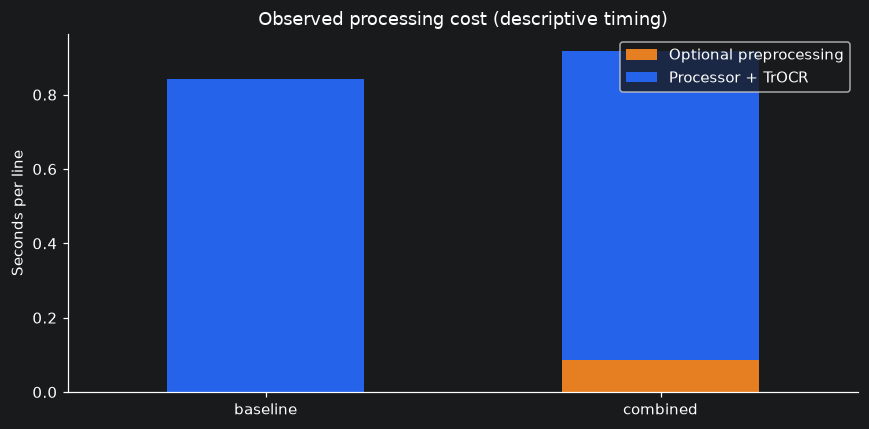

In [7]:
timing = summary[["preprocessing_seconds", "inference_seconds"]].div(summary["sample_count"], axis=0)
ax = timing.rename(columns={"preprocessing_seconds": "Optional preprocessing",
                            "inference_seconds": "Processor + TrOCR"}).plot.bar(
    stacked=True, figsize=(8, 4), color=["#e67e22", "#2563eb"], rot=0)
ax.set(xlabel="", ylabel="Seconds per line", title="Observed processing cost (descriptive timing)")
plt.tight_layout()
plt.savefig(run_dir / "processing_time.png", bbox_inches="tight")
plt.show()

## Where does preprocessing help or hurt?

The next plots pair each line with its own baseline. The scatter diagonal means equal CER. The count chart uses per-line CER to count improved, unchanged, and worsened lines; these counts are diagnostics, not corpus metrics or a statistical significance test. A technique can help many short lines and still worsen corpus CER if it damages longer lines.

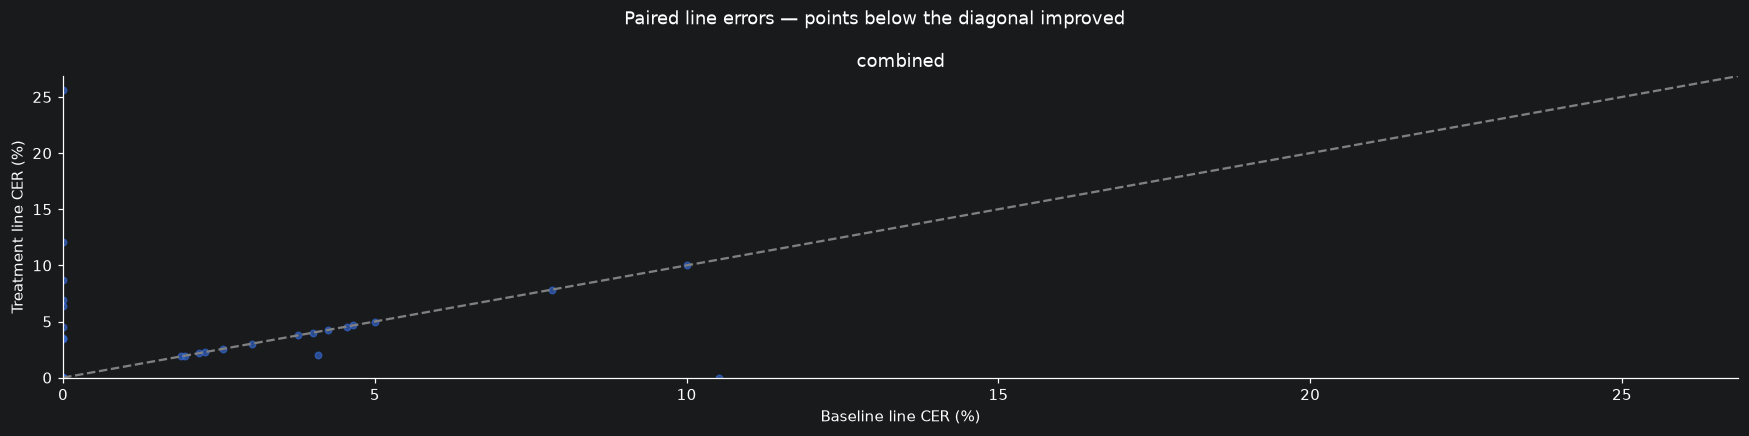

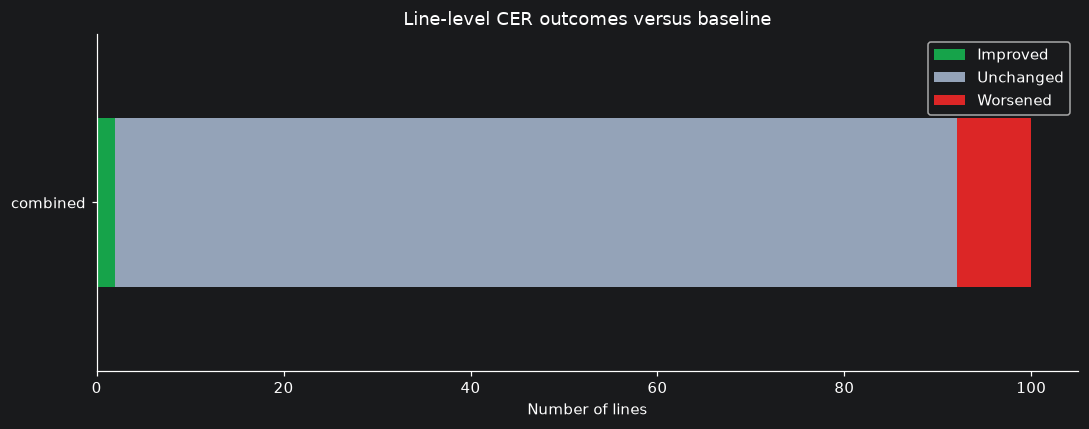

,Improved,Unchanged,Worsened
combined,2,90,8


In [8]:
paired = predictions.pivot(index="sample_id", columns="configuration", values="cer")
treatments = [name for name in pipelines if name != "baseline"]
fig, axes = plt.subplots(1, len(treatments), figsize=(16, 4), squeeze=False)
outcomes = {}
for ax, name in zip(axes[0], treatments):
    x, y = 100 * paired["baseline"], 100 * paired[name]
    limit = max(float(x.max()), float(y.max()), 1) * 1.05
    ax.scatter(x, y, alpha=0.6, s=18)
    ax.plot([0, limit], [0, limit], "--", color="gray")
    ax.set(xlim=(0, limit), ylim=(0, limit), xlabel="Baseline line CER (%)",
           ylabel="Treatment line CER (%)", title=name)
    delta = paired[name] - paired["baseline"]
    same = np.isclose(delta, 0, atol=1e-12, rtol=0)
    outcomes[name] = {"Improved": int(((delta < 0) & ~same).sum()),
                      "Unchanged": int(same.sum()),
                      "Worsened": int(((delta > 0) & ~same).sum())}
fig.suptitle("Paired line errors — points below the diagonal improved")
fig.tight_layout()
fig.savefig(run_dir / "paired_line_cer.png", bbox_inches="tight")
plt.show()
outcomes = pd.DataFrame.from_dict(outcomes, orient="index")
ax = outcomes.plot.barh(stacked=True, color=["#16a34a", "#94a3b8", "#dc2626"], figsize=(10, 4))
ax.set(xlabel="Number of lines", ylabel="", title="Line-level CER outcomes versus baseline")
plt.tight_layout()
plt.savefig(run_dir / "line_outcomes.png", bbox_inches="tight")
plt.show()
outcomes.to_csv(run_dir / "line_outcomes.csv")
display(outcomes)


combined | sample_480 | CER change -10.53 pp
Reference: resemblance to the shrunk heads we had
Baseline:  resentplace to the shrunk heads we had
Treatment: resemblance to the shrunk heads we had

combined | sample_43 | CER change +25.58 pp
Reference: 15,695 times in their different grammatical
Baseline:  15,695 times in their different grammatical
Treatment: " S.695 times in their different educational


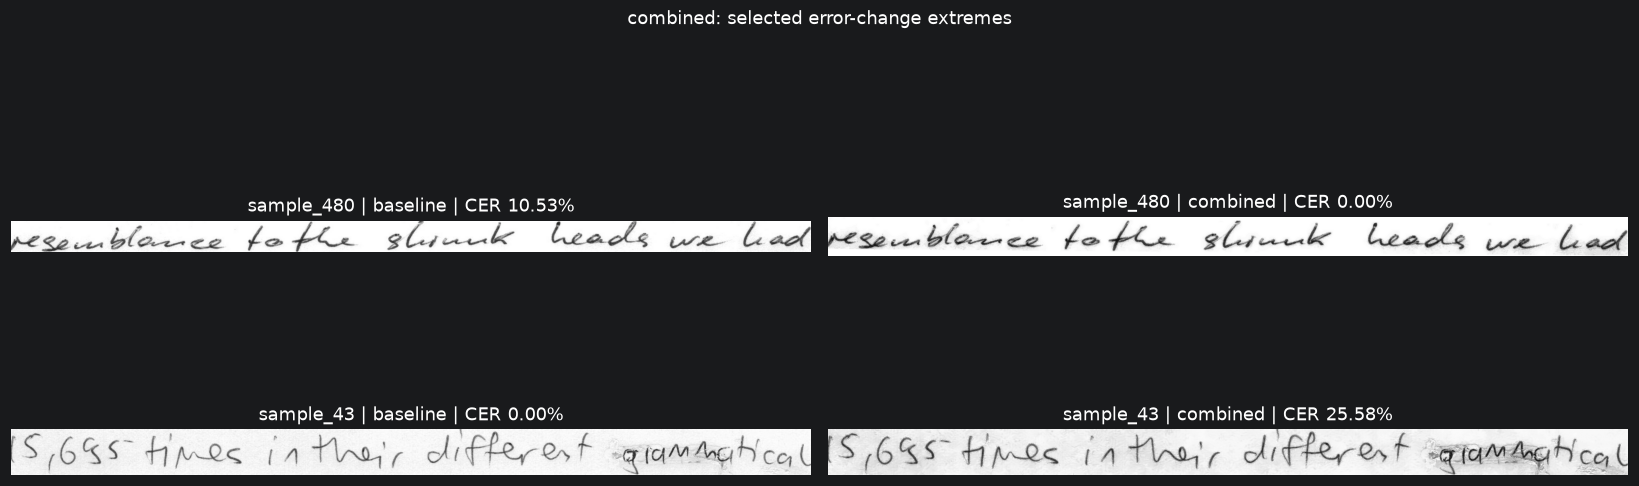

In [9]:
# Show each treatment's minimum and maximum CER change.
# These are deliberately selected extremes, not representative examples.
sample_by_id = {s["id"]: s for s in samples}
prediction_lookup = predictions.set_index(["sample_id", "configuration"])
for name in treatments:
    delta = paired[name] - paired["baseline"]
    if np.allclose(delta, 0, atol=1e-12, rtol=0):
        print(f"{name}: no line-level CER changes; showing the first selected line.")
        example_ids = [samples[0]["id"]]
    else:
        example_ids = list(dict.fromkeys([delta.idxmin(), delta.idxmax()]))
    fig, axes = plt.subplots(len(example_ids), 2, figsize=(15, 3 * len(example_ids)), squeeze=False)
    for row, sample_id in enumerate(example_ids):
        sample = sample_by_id[sample_id]
        for col, config in enumerate(("baseline", name)):
            image = pipelines[config](sample["image"])
            axes[row, col].imshow(image, cmap="gray", vmin=0, vmax=255)
            axes[row, col].set_title(f"{sample_id} | {config} | CER {100 * paired.loc[sample_id, config]:.2f}%")
            axes[row, col].axis("off")
        print(f"\n{name} | {sample_id} | CER change {100 * delta.loc[sample_id]:+.2f} pp")
        print("Reference:", sample["ground_truth"])
        print("Baseline: ", prediction_lookup.loc[(sample_id, "baseline"), "prediction"])
        print("Treatment:", prediction_lookup.loc[(sample_id, name), "prediction"])
    fig.suptitle(f"{name}: selected error-change extremes")
    fig.tight_layout()
    fig.savefig(run_dir / f"examples_{name}.png", bbox_inches="tight")
    plt.show()

## Interpretation

Compare corpus CER/WER against the freshly evaluated baseline. Negative percentage-point changes mean lower error; relative changes are undefined if baseline error is zero. Use paired plots and the printed predictions to inspect successes and failures. Selected extremes are not representative examples.

This experiment measures the complete ordered pipeline, not the contribution of individual stages. Improvements are not assumed: denoising or enhanced contrast may damage strokes, and deskewing can change canvas dimensions and the scaling during mandatory resizing. Grayscale has no pixel effect on already-L images.

Compare with Part 1 only when dataset revisions, indices, checkpoint, decoding, and normalization match. The initial runs share those settings. Further order or parameter exploration must remain on validation data. Full validation evaluation is the next step before a separate final test evaluation. Timing values describe this sequential CPU run and are not a speed benchmark.